
# Random Forest V2 — DDXPlus Data Exploration

## NLP-Assisted Symptom-Based Disease Prediction System

This notebook explores the training data used to develop the Random Forest V2 model.

The original dataset contains 21 respiratory conditions derived from DDXPlus. Two additional conditions, COVID-19 and allergic rhinitis, were included using reference-guided synthetic symptom scenarios, giving a total of 23 conditions.

The notebook presents:

1. Dataset overview
2. Distribution of the original 21 conditions
3. Distribution of all 23 conditions
4. Dataset summary and limitations

The synthetic scenarios were created for prototype development and do not represent real Kenyan patient records.


In [3]:

# Cell 2: Import libraries and load V2 dataset information

from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt

# Find the project root
ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "models/v2_feature_schema.json").is_file()
    ),
    None
)

assert ROOT is not None, "ML project folder not found"

# Load files saved inside the repository
SCHEMA_PATH = ROOT / "models" / "v2_feature_schema.json"
SUMMARY_PATH = ROOT / "reports" / "v2_dataset_summary.json"

assert SCHEMA_PATH.is_file(), "Feature schema not found"
assert SUMMARY_PATH.is_file(), "Dataset summary not found"

schema = json.loads(
    SCHEMA_PATH.read_text(encoding="utf-8")
)

summary = json.loads(
    SUMMARY_PATH.read_text(encoding="utf-8")
)

# Validate the dataset information
assert schema["feature_count"] == 66
assert summary["original_conditions"] == 21
assert summary["combined_conditions"] == 23
assert summary["combined_training_scenarios"] == 443867

print("RANDOM FOREST V2 - DATASET SETUP")
print("-------------------------------------")
print("Feature schema: FOUND")
print("Dataset summary: FOUND")
print("Numerical features:", schema["feature_count"])
print("Original conditions:", summary["original_conditions"])
print("Total conditions:", summary["combined_conditions"])
print("Total training scenarios:", summary["combined_training_scenarios"])

print("\nStep 2 PASSED!")


RANDOM FOREST V2 - DATASET SETUP
-------------------------------------
Feature schema: FOUND
Dataset summary: FOUND
Numerical features: 66
Original conditions: 21
Total conditions: 23
Total training scenarios: 443867

Step 2 PASSED!


In [4]:

# Cell 3: Original DDXPlus dataset overview

original_counts = pd.Series(
    summary["original_condition_counts"],
    dtype="int64"
)

# Verify the original dataset
assert len(original_counts) == 21
assert original_counts.sum() == 443067

print("DDXPLUS TRAINING DATASET OVERVIEW")
print("-------------------------------------")
print("Training scenarios:", original_counts.sum())
print("Numerical features:", schema["feature_count"])
print("Respiratory conditions:", len(original_counts))

print("\nFIRST 10 FEATURE NAMES")
print("-------------------------------------")

for feature in schema["feature_names"][:10]:
    print(feature)

print("\nTOP 5 CONDITIONS BY SCENARIO COUNT")
print("-------------------------------------")

print(
    original_counts.sort_values(
        ascending=False
    ).head(5)
)

print("\nStep 3 PASSED!")


DDXPLUS TRAINING DATASET OVERVIEW
-------------------------------------
Training scenarios: 443067
Numerical features: 66
Respiratory conditions: 21

FIRST 10 FEATURE NAMES
-------------------------------------
AGE
SEX_M
E_103__present
E_112__present
E_14__present
E_144__present
E_161__present
E_162__present
E_166__present
E_169__present

TOP 5 CONDITIONS BY SCENARIO COUNT
-------------------------------------
URTI                  64368
Viral pharyngitis     61642
Influenza             26812
Bronchitis            26400
Allergic sinusitis    26203
dtype: int64

Step 3 PASSED!


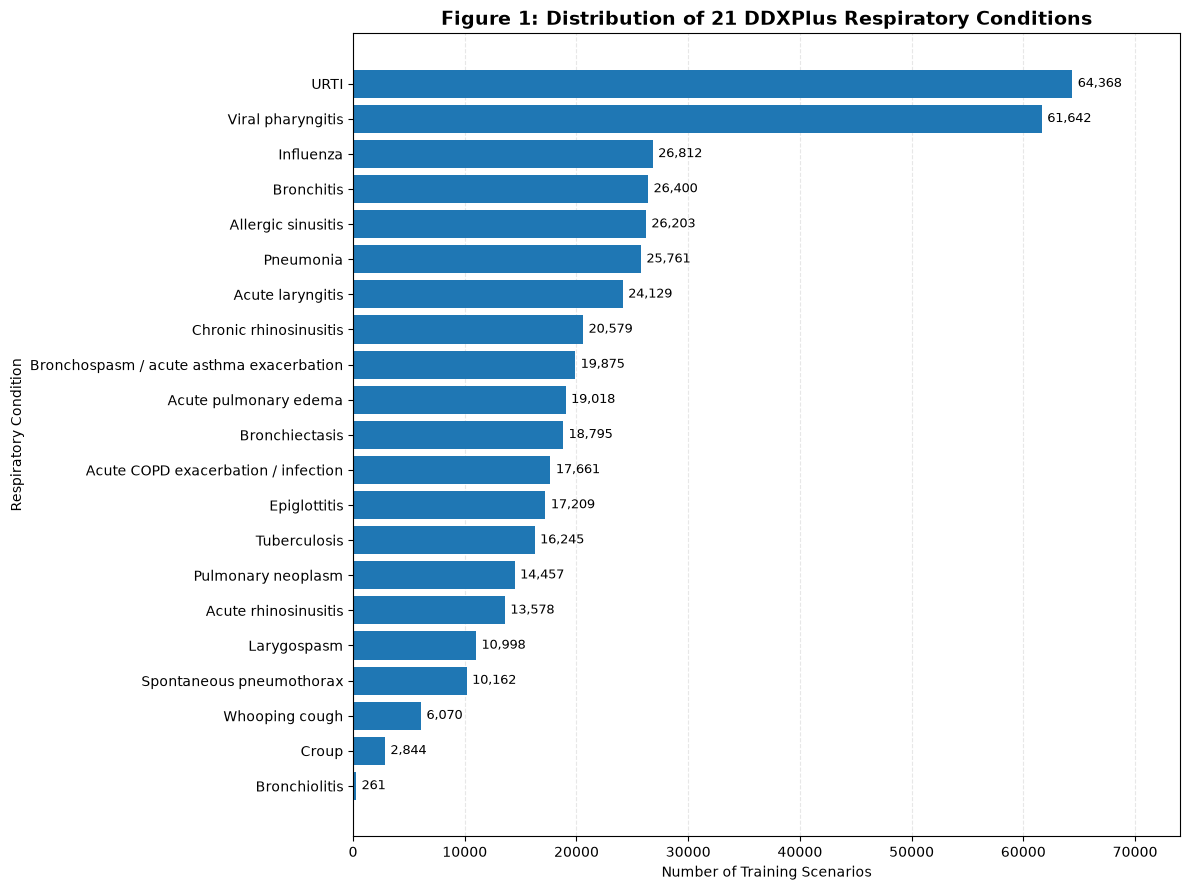

Total conditions: 21
Total training scenarios: 443067
Largest class: URTI
Graph saved: c:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\notebooks\v2\figures\v2_disease_distribution.png

Step 4 PASSED!


In [5]:

# Cell 4: Figure 1 - Distribution of the original 21 conditions

# Sort disease counts from smallest to largest
disease_counts = original_counts.sort_values()

# Create folder for figures
FIGURE_DIR = ROOT / "notebooks" / "v2" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Create the graph
fig, ax = plt.subplots(figsize=(12, 9))

bars = ax.barh(
    disease_counts.index,
    disease_counts.values
)

# Show number of scenarios beside each bar
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 500,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Figure 1: Distribution of 21 DDXPlus Respiratory Conditions",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Number of Training Scenarios")
ax.set_ylabel("Respiratory Condition")

ax.set_xlim(0, disease_counts.max() * 1.15)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Save the graph
figure_path = FIGURE_DIR / "v2_disease_distribution.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Total conditions:", len(disease_counts))
print("Total training scenarios:", disease_counts.sum())
print("Largest class:", disease_counts.idxmax())
print("Graph saved:", figure_path)

print("\nStep 4 PASSED!")


V2 COMBINED DATASET OVERVIEW
-------------------------------------
Total training scenarios: 443867
Total conditions: 23
DDXPlus-derived scenarios: 443067
Synthetic scenarios: 800


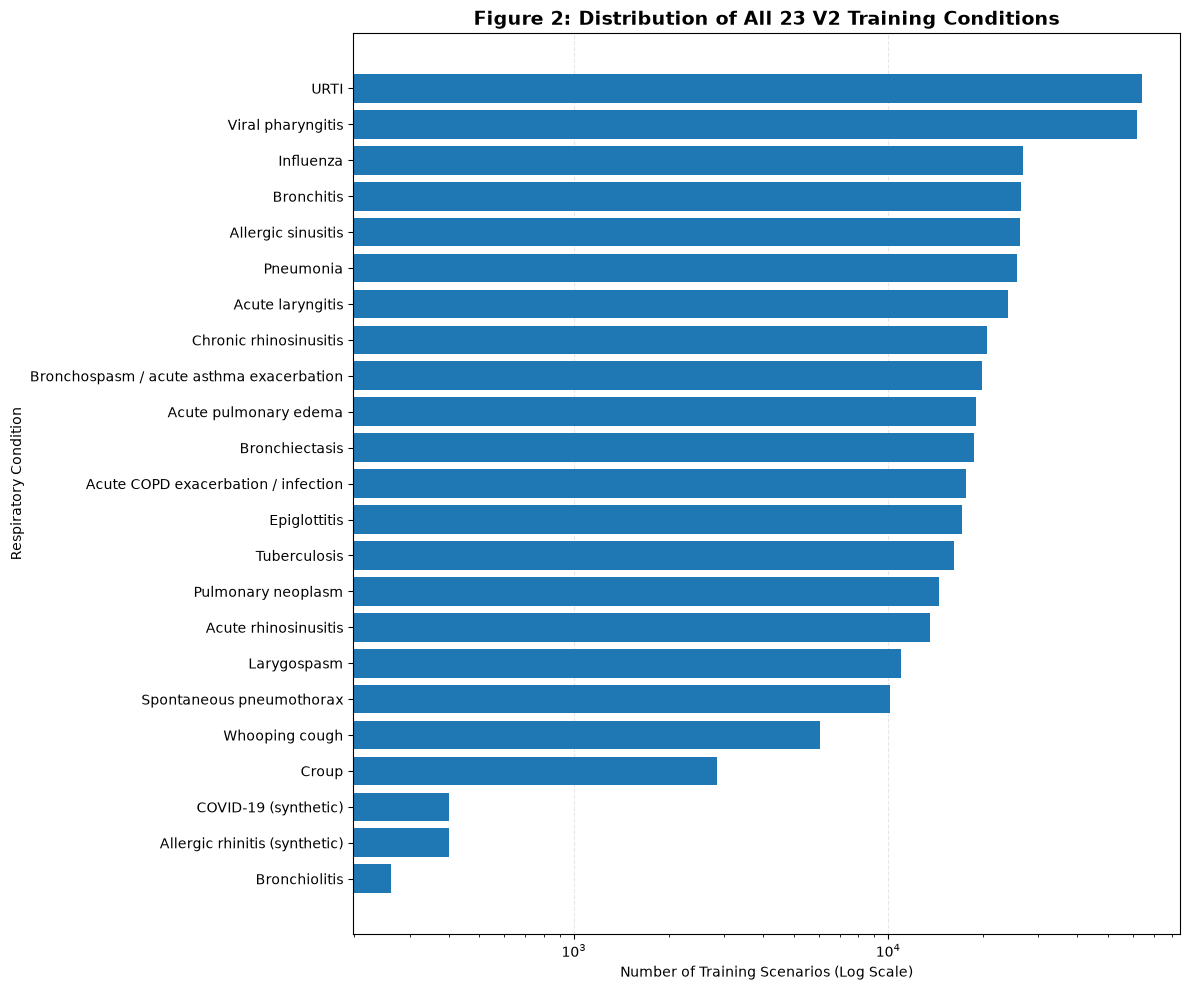


Synthetic conditions:
COVID-19             400
Allergic rhinitis    400
dtype: int64

Graph saved: c:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\notebooks\v2\figures\v2_23_condition_distribution.png
Note: Synthetic scenarios are not real patient records.

Step 5 PASSED!


In [6]:

# Cell 5: Figure 2 - Distribution of all 23 conditions

# Load the combined training condition counts
combined_counts = pd.Series(
    summary["combined_condition_counts"],
    dtype="int64"
)

synthetic_conditions = [
    "COVID-19",
    "Allergic rhinitis"
]

# Verify the combined dataset
assert len(combined_counts) == 23
assert combined_counts.sum() == 443867

ddxplus_count = combined_counts.drop(
    synthetic_conditions
).sum()

synthetic_count = combined_counts.loc[
    synthetic_conditions
].sum()

assert ddxplus_count == 443067
assert synthetic_count == 800

print("V2 COMBINED DATASET OVERVIEW")
print("-------------------------------------")
print("Total training scenarios:", combined_counts.sum())
print("Total conditions:", len(combined_counts))
print("DDXPlus-derived scenarios:", ddxplus_count)
print("Synthetic scenarios:", synthetic_count)

# Sort conditions from smallest to largest
plot_counts = combined_counts.sort_values()

# Label the two synthetic conditions
labels = [
    f"{name} (synthetic)"
    if name in synthetic_conditions
    else name
    for name in plot_counts.index
]

# Create graph
fig, ax = plt.subplots(figsize=(12, 10))

bars = ax.barh(
    labels,
    plot_counts.values
)

# Use logarithmic scale to show small and large classes
ax.set_xscale("log")

ax.set_title(
    "Figure 2: Distribution of All 23 V2 Training Conditions",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Number of Training Scenarios (Log Scale)")
ax.set_ylabel("Respiratory Condition")

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()

# Save Figure 2
figure_2_path = (
    FIGURE_DIR / "v2_23_condition_distribution.png"
)

fig.savefig(
    figure_2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSynthetic conditions:")
print(combined_counts.loc[synthetic_conditions])

print("\nGraph saved:", figure_2_path)
print("Note: Synthetic scenarios are not real patient records.")

print("\nStep 5 PASSED!")



## Dataset Summary and Limitations

### Dataset Summary

The Random Forest V2 training dataset contains 443,867 scenarios covering 23 respiratory conditions. The original 21 conditions were derived from DDXPlus, while COVID-19 and allergic rhinitis were added using 800 reference-guided synthetic scenarios.

The model uses 66 numerical features, including age, sex, and encoded symptom information.

### Key Observations

- The dataset is imbalanced, with some conditions having significantly more training scenarios than others.
- URTI has the largest number of scenarios, while bronchiolitis has the fewest among the original conditions.
- COVID-19 and allergic rhinitis each have 400 synthetic scenarios.
- A logarithmic scale was used in Figure 2 to make differences between smaller and larger classes easier to see.

### Limitations

The DDXPlus-derived records are simulated clinical cases rather than real patient records. The additional COVID-19 and allergic rhinitis scenarios are synthetic and based on assumed symptom patterns.

Therefore, the dataset does not represent the actual distribution of respiratory diseases in Kenya.

Class imbalance and limited symptom diversity may also affect prediction performance, especially for the two added conditions.

The system is intended for preliminary health awareness and should not be used as a medical diagnosis tool.
